In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import pickle
from glob import glob
from shapely.geometry import Polygon, Point
import warnings
import glob
import matplotlib.font_manager as fm
import os
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator

# 忽略不必要的警告
warnings.filterwarnings('ignore')

In [5]:
# 数据路径
DATA_DIR = r'F:\ygp\SWOTHRD\datunhai'
# 纳木错边界路径
NAMCO_BOUNDARY = r'F:\ygp\ygp湖泊边界\datun_shp'

# VS 区域坐标 (选取虚拟站点，从gee获取站点坐标)
vs_coords = [
    (103.3147426551886, 23.398075099917143),
    (103.31603011551574, 23.400438258524883),
    (103.3132835334845, 23.40248629520073),
    (103.31139525833801, 23.400044401685893),
    (103.3147426551886, 23.398075099917143)
]
vs_polygon = Polygon(vs_coords)

In [6]:
def iterative_sigma_clipping(wse_values, threshold_std=0.1):
    """
    1. 反复计算均值和标准差
    2. 剔除超出 ±2σ 的像素
    3. 直到标准差稳定在 < 0.1m
    """
    data = wse_values[~np.isnan(wse_values)]
    if len(data) == 0:
        return np.nan, np.nan
    
    current_std = np.std(data)
    current_mean = np.mean(data)
    
    # 迭代剔除
    iteration = 0
    while current_std > threshold_std and len(data) > 5:
        # 计算 ±2σ 范围
        lower = current_mean - 2 * current_std
        upper = current_mean + 2 * current_std
        
        # 筛选
        mask = (data >= lower) & (data <= upper)
        new_data = data[mask]
        
        # 如果数据不再减少，停止迭代防止死循环
        if len(new_data) == len(data):
            break
            
        data = new_data
        current_std = np.std(data)
        current_mean = np.mean(data)
        iteration += 1
        
    return current_mean, current_std

In [7]:
# 根据你的实际路径修改
nc_files = glob.glob(os.path.join(DATA_DIR, "*.nc"))
print(f"找到 {len(nc_files)} 个 nc 文件")

找到 1955 个 nc 文件


每个文件中提取指定的“虚拟站（VS）区域”内的水位（WSE）数据，做质量过滤和异常值剔除，最后汇总成一个按日期排序的时间序列表

In [8]:
results = []

for file_path in nc_files:
    filename = os.path.basename(file_path)
    if "_100m_" not in filename:
        continue  # 如果不是 100m 文件（例如 250m），直接跳过
    
    ds = None
    try:
        # 1. 尝试打开 'data' 组（这是 SWOT HR 栅格产品的标准结构）
        try:
            ds = xr.open_dataset(file_path, group="data")
        except Exception:
            # 如果没有 'data' 组，尝试打开根目录
            ds = xr.open_dataset(file_path)

        # 2. 自动识别经纬度和水位变量名
        lat_attr = "latitude" if "latitude" in ds else "lat"
        lon_attr = "longitude" if "longitude" in ds else "lon"
        qual_attr = "wse_qual" if "wse_qual" in ds else "wse_qual_flag"

        # 3. 提取数据并转为 numpy 数组进行空间筛选
        lats = ds[lat_attr].values
        lons = ds[lon_attr].values
        wse_all = ds.wse.values
        qual_all = ds[qual_attr].values

        # VS 区域掩膜 (使用虚拟坐标范围)
        spatial_mask = (
            (lons >= 103.3113)
            & (lons <= 103.3161)
            & (lats >= 23.3980)
            & (lats <= 23.4025)
        )

        # 质量过滤 + 空间过滤 + 非空检查
        valid_mask = spatial_mask & (qual_all <= 1) & (~np.isnan(wse_all))
        vs_pixels = wse_all[valid_mask]

        # 4. 执行迭代剔除逻辑
        if len(vs_pixels) > 1:
            final_mean, final_std = iterative_sigma_clipping(vs_pixels)

            # 提取日期 (从属性中获取)
            date_str = ds.attrs.get(
                "time_coverage_start", filename.split("_")[-5][:8]
            )
            date_val = pd.to_datetime(date_str)

            if not np.isnan(final_mean):
                results.append(
                    {
                        "date": date_val,
                        "wse_mean": final_mean,
                        "wse_std": final_std,
                        "valid_count": len(vs_pixels),
                        "file": filename,  # 记录文件名，方便溯源
                    }
                )

    except Exception as e:
        print(f"Error processing {filename}: {e}")
    finally:
        if ds is not None:
            ds.close()

# 整理结果（同一天若有升降轨重叠，保留有效像元最多的一条）
df_results = pd.DataFrame(results)

if not df_results.empty:
    df_results["day"] = df_results["date"].dt.normalize()  # 抹去时分秒
    df_results = df_results.sort_values(
        "valid_count", ascending=False
    ).drop_duplicates(subset=["day"])
    df_results = (
        df_results.sort_values("date")
        .drop(columns=["day"])
        .reset_index(drop=True)
    )

print(f"Done! Successfully processed {len(df_results)} records (100m only).")

Done! Successfully processed 133 records (100m only).


可视化水位

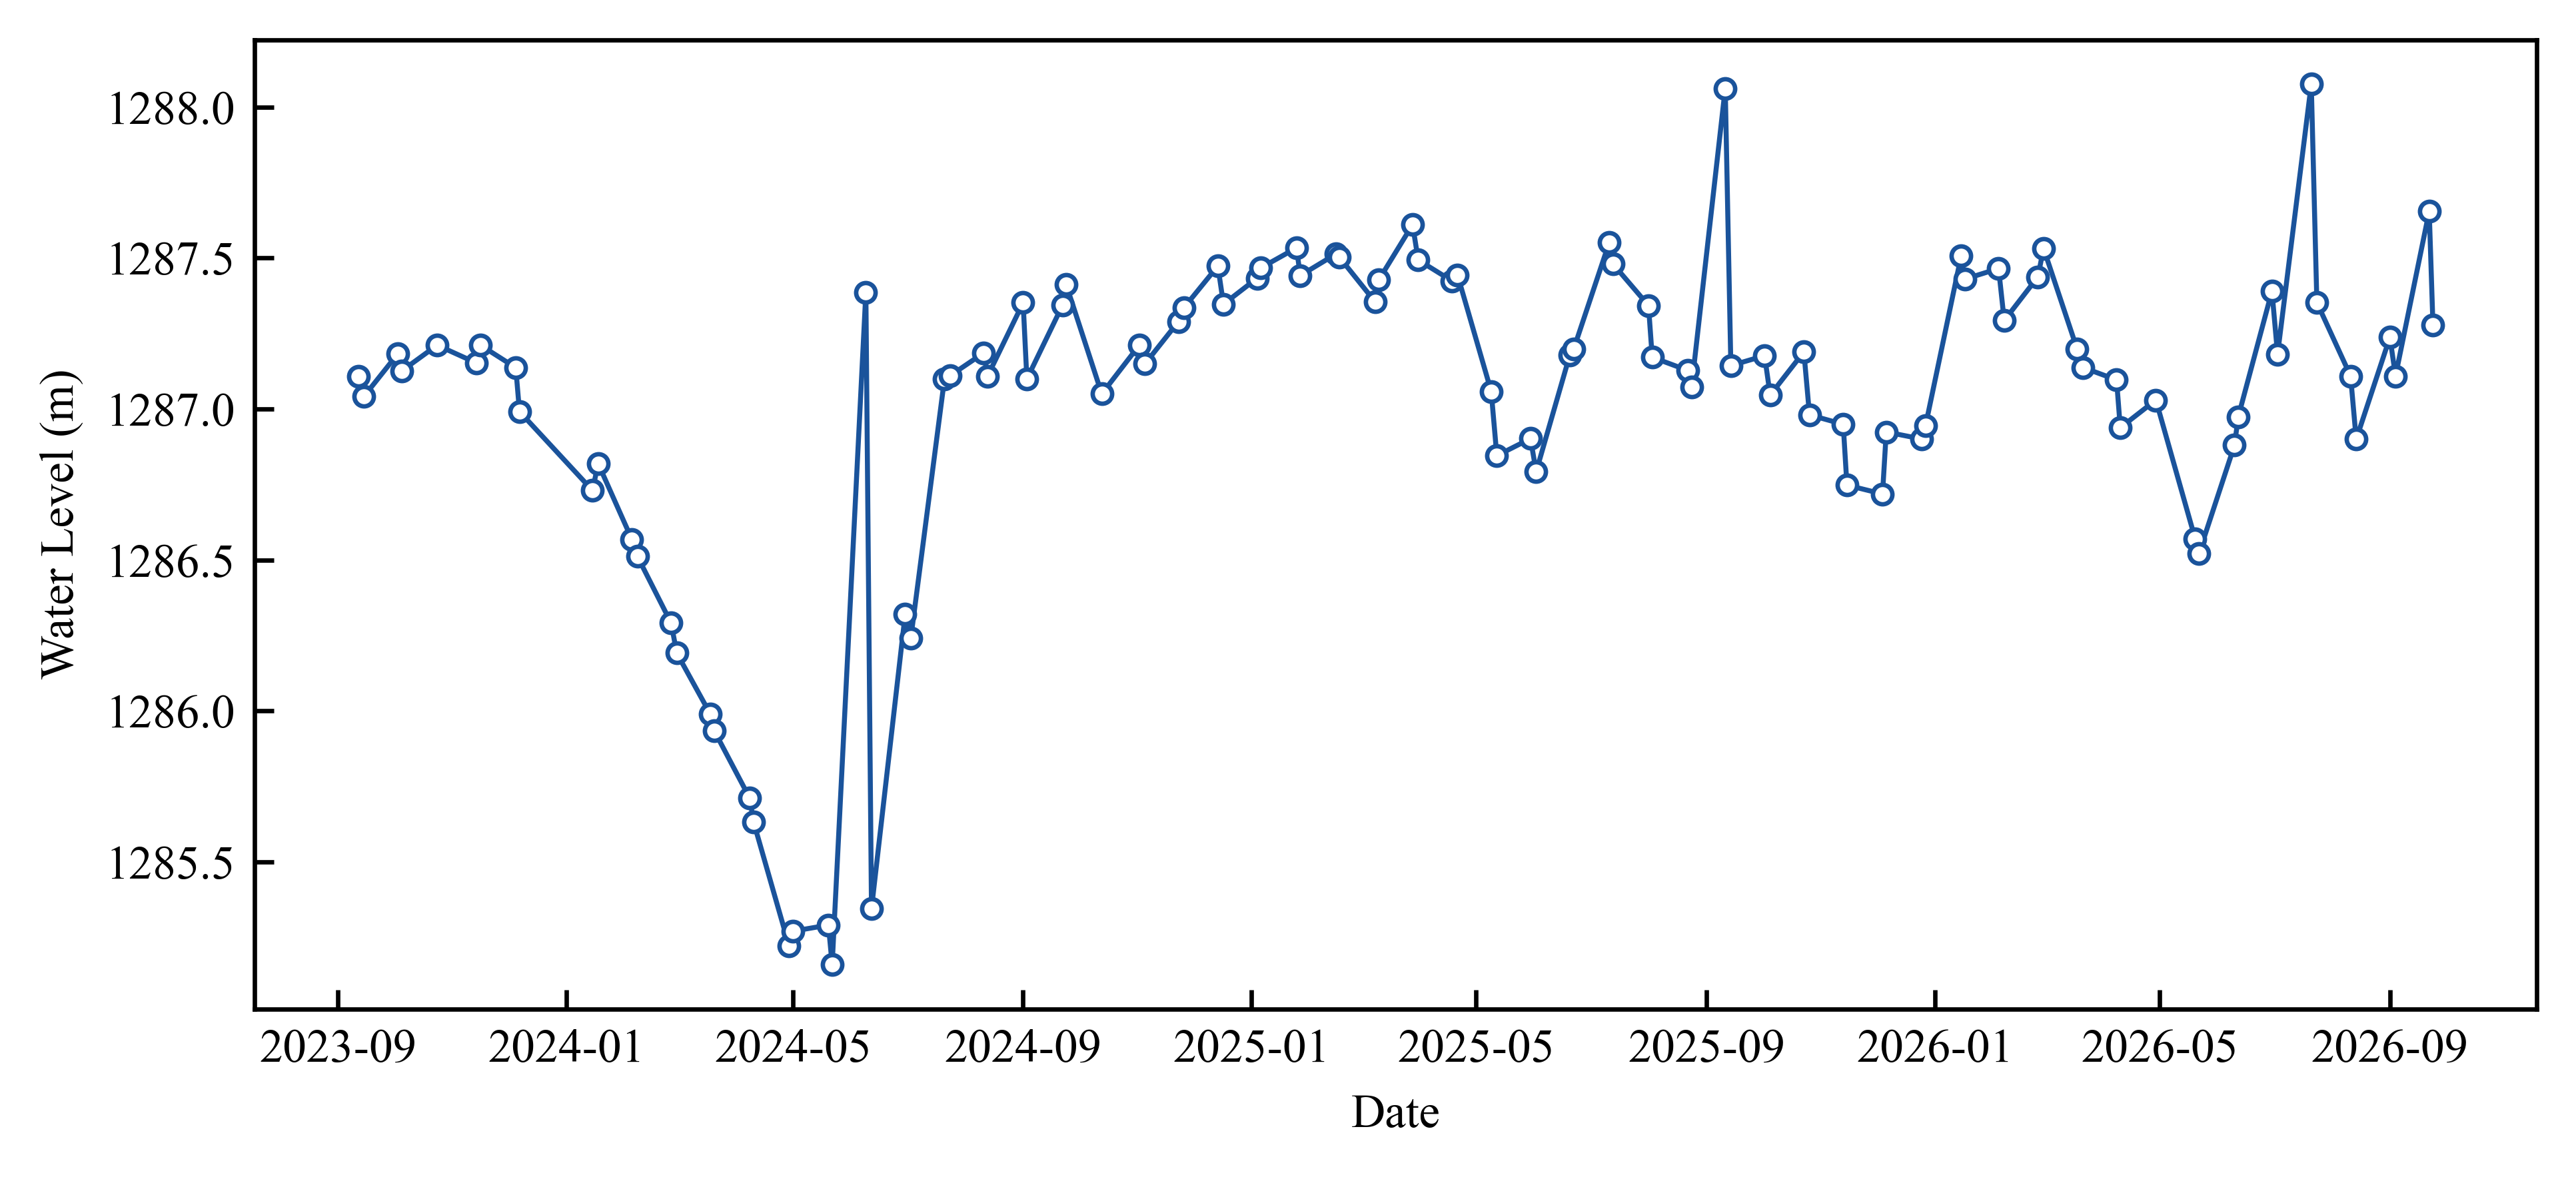

In [ ]:
# 1. 数据处理：按日期分组求水位均值
df_results['date'] = pd.to_datetime(df_results['date']).dt.floor('D') # 确保只保留到“日”
df_100m = (df_results[df_results['date'] >= '2023-09-01']
           .groupby('date', as_index=False)['wse_mean'].mean()
           .sort_values('date'))

# 2. 全局字体与样式设置
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 8.5
plt.rcParams['axes.unicode_minus'] = False

# 3. 绘图
fig, ax = plt.subplots(figsize=(6.5, 3.0), dpi=600)

ax.plot(df_100m['date'], df_100m['wse_mean'], 
        color='#1a539b', lw=0.9, 
        marker='o', ms=3.5, mfc='white', mec='#1a539b', mew=0.8)

# 4. 坐标轴设置
ax.tick_params(direction='in', top=False, right=False, length=3.5, width=0.8)
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m)')

plt.tight_layout()
plt.show()

封装数据并转为表格

In [15]:
# 1. 参数与路径配置
LAKE_NAME = "datunhai"  # 当前处理的湖泊名称
SAVE_DIR = r"F:\ygp\SWOTpkl"  # 保存路径
START_DATE = "2023-09-01"  # 筛选科学任务期起始时间

path_pickle = os.path.join(SAVE_DIR, f"{LAKE_NAME}_SWOT_wse_2023-2026.pkl")
path_excel = os.path.join(SAVE_DIR, f"{LAKE_NAME}_SWOT_wse_2023-2026.xlsx")

#2. 数据清洗与同日多轨优选
df_clean = df_results.copy()

# (1) 时间归一化：抹去具体时分秒
df_clean["date"] = pd.to_datetime(df_clean["date"]).dt.normalize()

# (2) 按照日期优选：同一天若有多轨，严格保留有效像元(valid_count)最多的一条
df_clean = df_clean.sort_values(
    ["date", "valid_count"], ascending=[True, False]
)
df_clean = (
    df_clean.drop_duplicates(subset=["date"])
    .sort_values("date")
    .reset_index(drop=True)
)

# (3) 筛选起始时间
df_clean = df_clean[df_clean["date"] >= START_DATE].copy()

# (4) 整理列顺序并四舍五入
cols_order = [
    c
    for c in ["date", "wse_mean", "wse_std", "valid_count", "file"]
    if c in df_clean.columns
]
output_df = df_clean[cols_order].reset_index(drop=True)

output_df["wse_mean"] = output_df["wse_mean"].round(3)
if "wse_std" in output_df.columns:
    output_df["wse_std"] = output_df["wse_std"].round(3)

# 将日期转为纯年月日字符串 (例如 2023-09-04)
output_df["date"] = output_df["date"].dt.strftime("%Y-%m-%d")


In [16]:
if not os.path.exists(SAVE_DIR):
    os.makedirs(SAVE_DIR)

try:
    # 1. 保存为 Pickle 文件
    output_df.to_pickle(path_pickle)
    print(f"Pickle 文件已保存: {path_pickle}")

    # 2. 保存为 Excel 文件
    output_df.to_excel(path_excel, index=False)
    print(f"Excel 文件已保存: {path_excel}")

    print("\n数据预览（前 5 条）：")
    display(output_df.head())

except Exception as e:
    print(f"文件保存失败，原因: {e}")

Pickle 文件已保存: F:\ygp\SWOTpkl\datunhai_SWOT_wse_2023-2026.pkl
Excel 文件已保存: F:\ygp\SWOTpkl\datunhai_SWOT_wse_2023-2026.xlsx

数据预览（前 5 条）：


,date,wse_mean,wse_std,valid_count,file
0,2023-09-12,1287.108032,0.115,14,SWOT_L2_HR_Raster_100m_UTM48Q_N_x_x_x_003_327_...
1,2023-09-15,1287.041992,0.090,22,SWOT_L2_HR_Raster_100m_UTM48Q_N_x_x_x_003_396_...
2,2023-10-03,1287.182007,0.060,21,SWOT_L2_HR_Raster_100m_UTM48Q_N_x_x_x_004_327_...
3,2023-10-05,1287.125000,0.075,21,SWOT_L2_HR_Raster_100m_UTM48Q_N_x_x_x_004_396_...
4,2023-10-24,1287.211060,0.092,22,SWOT_L2_HR_Raster_100m_UTM48Q_N_x_x_x_005_327_...


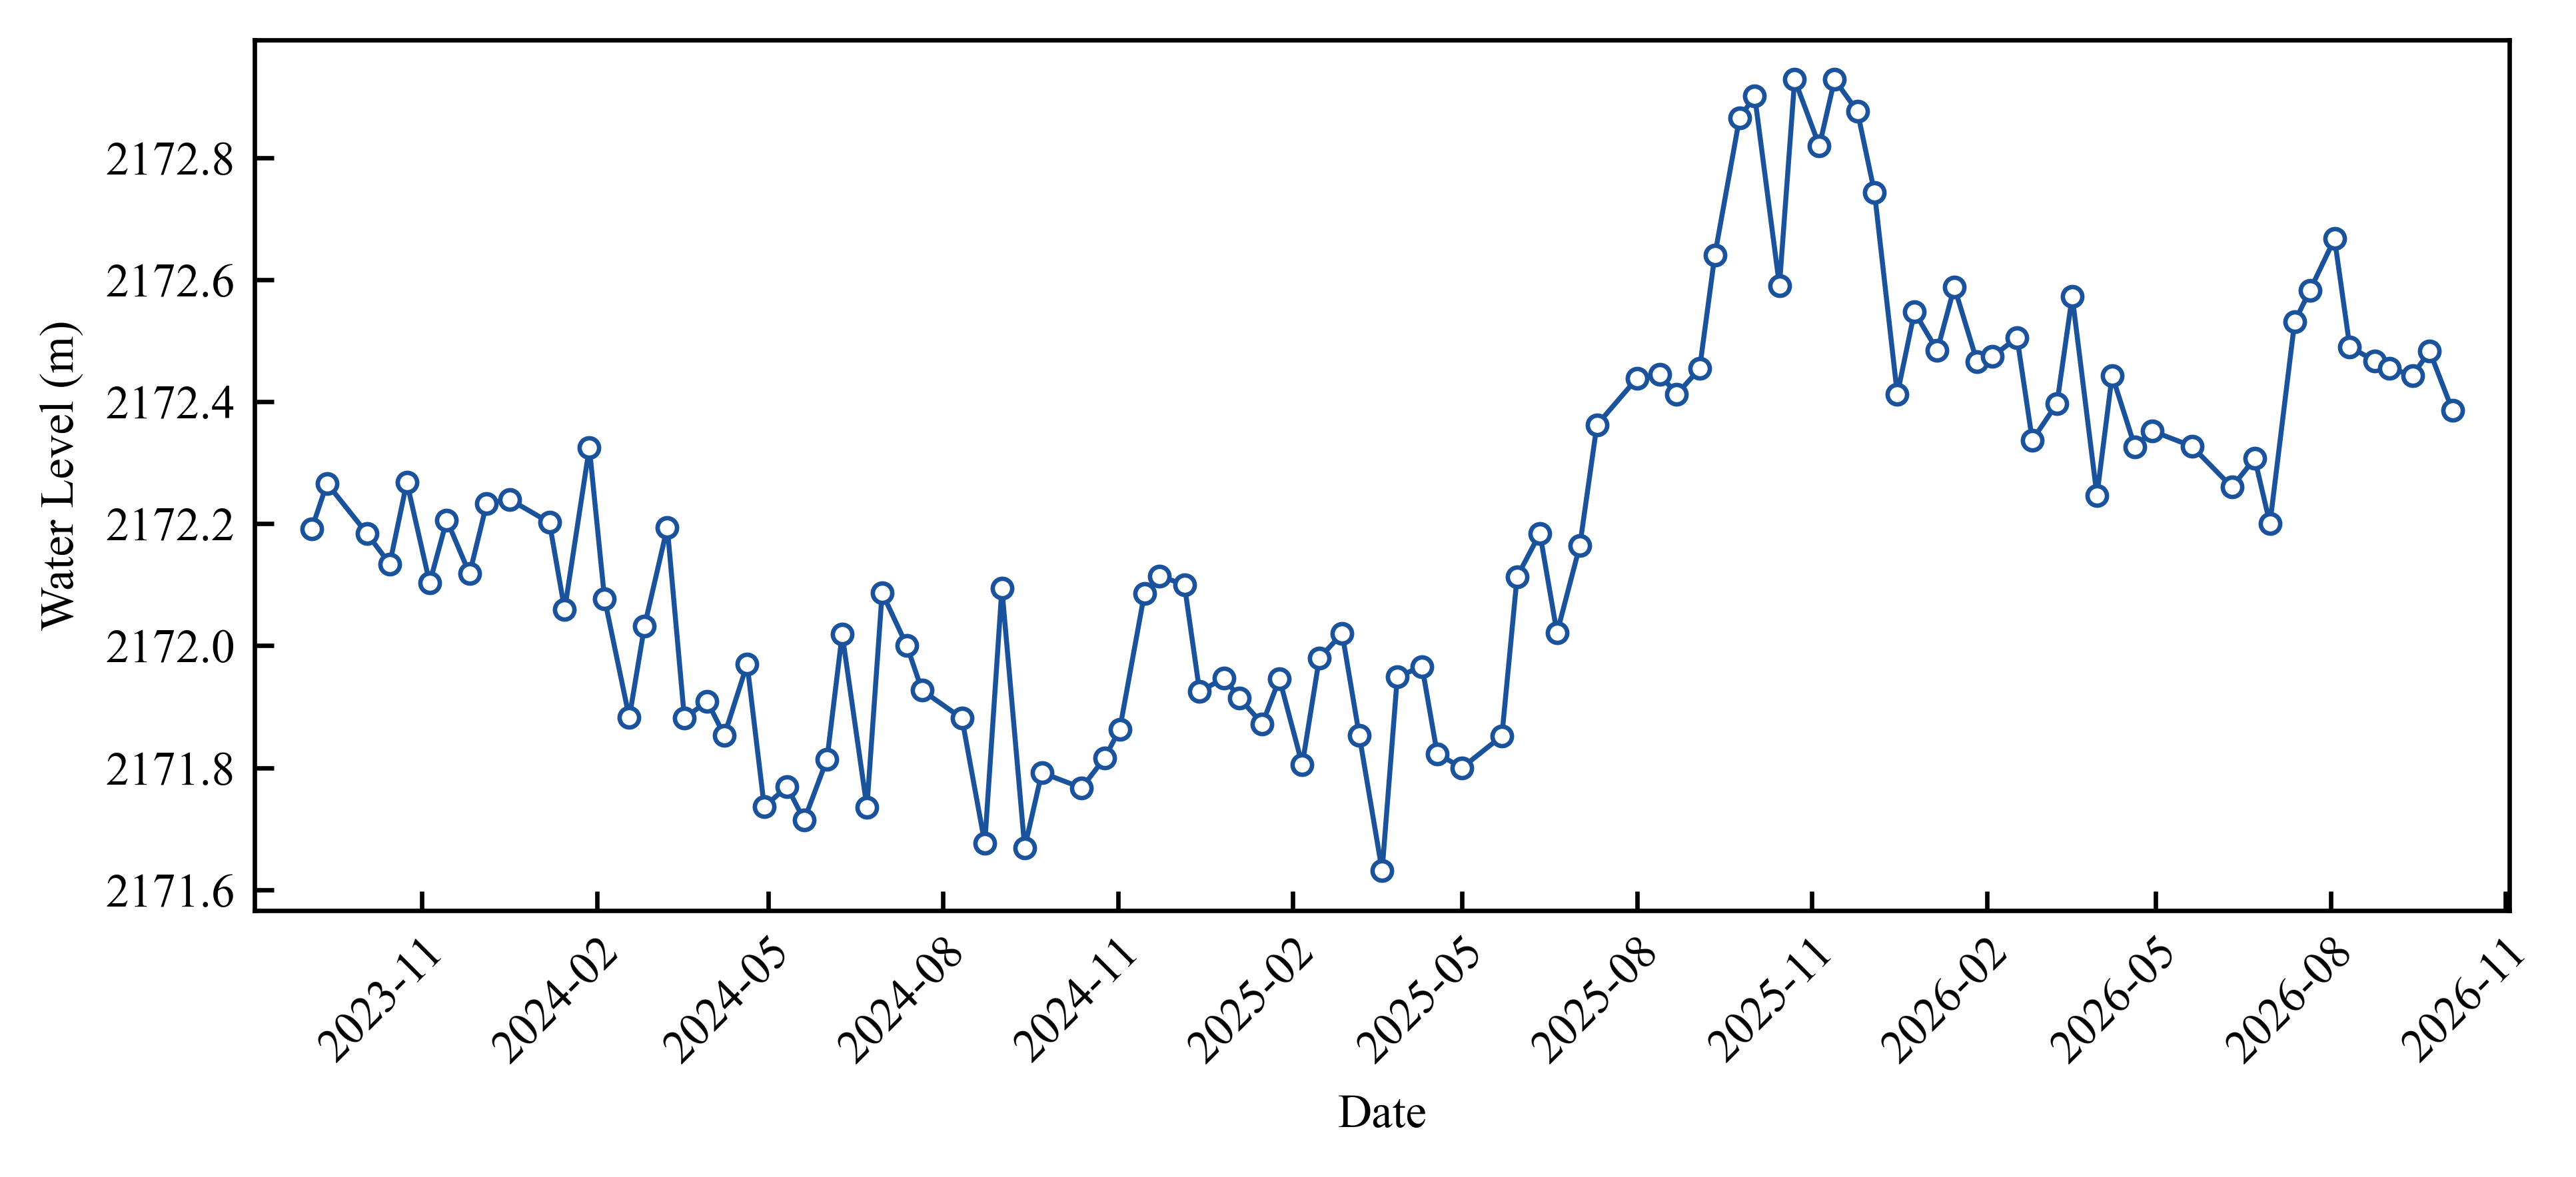

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1. 读取 pkl 数据
# =========================
df_results = pd.read_pickle('F:\ygp\SWOTpkl\caohai\Caohai_SWOT_wse_2023-2026.pkl')

# 如果 pkl 中是字典（例如 {'data': df}），请按实际结构调整，例如：
# df_results = pd.read_pickle('你的文件路径.pkl')['data']

# =========================
# 2. 数据处理：按日期分组求水位均值
# =========================
df_results['date'] = pd.to_datetime(df_results['date']).dt.floor('D')  # 只保留到“日”

df_100m = (df_results[df_results['date'] >= '2023-09-01']
           .groupby('date', as_index=False)['wse_mean'].mean()
           .sort_values('date'))
# df_100m = df_100m[(df_100m["wse_mean"] >= 2171.0)].copy()

# =========================
# 3. 全局字体与样式设置
# =========================
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 8.5
plt.rcParams['axes.unicode_minus'] = False

# 3. 绘图
fig, ax = plt.subplots(figsize=(6.5, 3.0), dpi=600)

ax.plot(df_100m['date'], df_100m['wse_mean'], 
        color='#1a539b', lw=0.9, 
        marker='o', ms=3.5, mfc='white', mec='#1a539b', mew=0.8)

# 4. 坐标轴设置
ax.tick_params(direction='in', top=False, right=False, length=3.5, width=0.8)
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m)')

# ================= 重点修改：横坐标刻度优化 =================

# 1) 设置主刻度的格式：显示年份和月份，例如 "2024-01"
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# 2) 设置主刻度的间隔：比如每 3 个月显示一个刻度 (如果想更宽，可以改为 6)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))

# 3) 旋转标签，防止重叠（旋转 45 度），并设置右对齐
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

# 4) (可选) 如果想要略微扩充两端的边界，防止两头贴边，可以加上这一句
ax.set_xlim(df_100m['date'].min() - pd.Timedelta(days=30), 
            df_100m['date'].max() + pd.Timedelta(days=30))

# ============================================================

plt.tight_layout() # 确保旋转后的标签不会被截断
plt.show()